In [1]:
from torchvision import datasets, transforms
import numpy as np
import torch
from torch.utils.data.sampler import SubsetRandomSampler
import torch.nn as nn
import torch.nn.functional as F

Tamaño 64x64, 5k muestras, 25 epochs

# 1. Llevar el conjunto de datos al entorno

In [2]:
# Para TRAIN: con augmentation
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

# Para VALID y TEST: sin augmentation (las fotos tal cual)
transform_eval = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

In [3]:
ruta = 'datasets_procesados/size_64x64/sample_5k'
train_data = datasets.ImageFolder(ruta, transform=transform_train)
eval_data  = datasets.ImageFolder(ruta, transform=transform_eval)

In [4]:
np.random.seed(42)
test_size = 0.2
valid_size = 0.2
batch_size = 16 

# For test
num_data = len(train_data)
indices_data = list(range(num_data)) 
np.random.shuffle(indices_data)
split_tt = int(np.floor(test_size * num_data))
train_idx, test_idx = indices_data[split_tt:], indices_data[:split_tt]


# For Valid
num_train = len(train_idx)
np.random.shuffle(train_idx)
split_tv = int(np.floor(valid_size * num_train))
train_final_idx = train_idx[split_tv:]
valid_idx = train_idx[:split_tv]
train_idx = train_final_idx  


# define samplers for obtaining training and validation batches
train_sampler = SubsetRandomSampler(train_idx)
test_sampler = SubsetRandomSampler(test_idx)
valid_sampler = SubsetRandomSampler(valid_idx)


# - Imágenes: bloque numérico de 4 dimensiones que agrupa las fotos del lote: {Forma (Shape):  [batch_size, canales, alto, ancho]
# - Etiquetas:  lista con la clase real que corresponde a cada una de las 16 imágenes del paquete: [0,1,1,0,...]
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, sampler=train_sampler, num_workers=0)
valid_loader = torch.utils.data.DataLoader(eval_data, batch_size=batch_size, sampler=valid_sampler, num_workers=0)  # ← eval_data
test_loader = torch.utils.data.DataLoader(eval_data, sampler=test_sampler, batch_size=batch_size, num_workers=0)  # ← eval_data

# variable representing classes of the images
classes = [0, 1]

# 2. Inicialización de la CNN

Inicializamos el modelo:

In [5]:
torch.manual_seed(42)
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        # convolutional layer
        self.conv1 = nn.Conv2d(3, 16, 5) 
        # max pooling layer
        self.pool = nn.MaxPool2d(2, 2) 
        self.conv2 = nn.Conv2d(16, 32, 5)
        self.dropout = nn.Dropout(0.2) 
        # NOTA
        self.fc1 = nn.Linear(32 * 13 * 13, 256) 
        self.fc2 = nn.Linear(256, 84) 
        self.fc3 = nn.Linear(84, 2) 
        self.softmax = nn.LogSoftmax(dim=1)
        
    def forward(self, x): 
      
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.dropout(x) 
        x = x.view(-1, 32 * 13 * 13) 
        
        x = F.relu(self.fc1(x))
        x = self.dropout(F.relu(self.fc2(x)))
        x = self.softmax(self.fc3(x))
        return x
    
# create a complete CNN
model = Net()


# criterion = torch.nn.CrossEntropyLoss()
criterion = torch.nn.NLLLoss()
# Optimizer: Descenso de Gradiente Estocástico.
optimizer = torch.optim.SGD(model.parameters(), lr = 0.003, momentum= 0.9) # lr = tasa de aprendizaje. momentum: no entiendo bien 

# 3. Entrenar el modelo

In [6]:
# Definimos la variable manualmente
train_on_gpu = torch.cuda.is_available()

# Si hay GPU, también enviamos el modelo a la tarjeta gráfica
if train_on_gpu:
    print('CUDA disponible. El entrenamiento se ejecutará en la GPU.')
    model.cuda()
else:
    print('CUDA no disponible. El entrenamiento se ejecutará en la CPU.')

CUDA no disponible. El entrenamiento se ejecutará en la CPU.


In [7]:
# number of epochs to train the model
n_epochs = 25 

valid_loss_min = np.inf # track change in validation loss


historial_train = []   # ← NUEVO
historial_valid = []   # ← NUEVO



for epoch in range(1, n_epochs+1):

    # keep track of training and validation loss
    train_loss = 0.0
    valid_loss = 0.0
    
    # train the model #
    model.train()
    for data, target in train_loader:
        # move tensors to GPU if CUDA is available
        if train_on_gpu:
            data, target = data.cuda(), target.cuda()
        # clear the gradients of all optimized variables
        optimizer.zero_grad()
        # forward pass: compute predicted outputs by passing inputs to the model
        output = model(data)
        # calculate the batch loss
        loss = criterion(output, target)
        # backward pass: compute gradient of the loss with respect to model parameters
        loss.backward()
        # perform a single optimization step (parameter update)
        optimizer.step()
        # update training loss
        train_loss += loss.item()*data.size(0)
        
    # Validating the model
    model.eval()
    for data, target in valid_loader:
        if train_on_gpu:
            data, target = data.cuda(), target.cuda()
        # forward pass: compute predicted outputs by passing inputs to the model
        output = model(data)
        # calculate the batch loss
        loss = criterion(output, target)
        # update average validation loss 
        valid_loss += loss.item()*data.size(0)
    

    train_loss = train_loss / len(train_sampler)
    valid_loss = valid_loss / len(valid_sampler)

    historial_train.append(train_loss)   # ← NUEVO
    historial_valid.append(valid_loss)   # ← NUEVO



        
    # print training/validation statistics 
    print('Epoch: {} \tTraining Loss: {:.6f} \tValidation Loss: {:.6f}'.format(
        epoch, train_loss, valid_loss))
    
    # save model if validation loss has decreased
    if valid_loss <= valid_loss_min:
        print('Validation loss decreased ({:.6f} --> {:.6f}).  Saving model ...'.format(
        valid_loss_min,
        valid_loss))
        torch.save(model.state_dict(), 'model_64x64_5k.pt')
        valid_loss_min = valid_loss

Epoch: 1 	Training Loss: 0.685046 	Validation Loss: 0.671189
Validation loss decreased (inf --> 0.671189).  Saving model ...
Epoch: 2 	Training Loss: 0.659631 	Validation Loss: 0.646825
Validation loss decreased (0.671189 --> 0.646825).  Saving model ...
Epoch: 3 	Training Loss: 0.637107 	Validation Loss: 0.625624
Validation loss decreased (0.646825 --> 0.625624).  Saving model ...
Epoch: 4 	Training Loss: 0.622340 	Validation Loss: 0.634564
Epoch: 5 	Training Loss: 0.616055 	Validation Loss: 0.571013
Validation loss decreased (0.625624 --> 0.571013).  Saving model ...
Epoch: 6 	Training Loss: 0.589752 	Validation Loss: 0.552588
Validation loss decreased (0.571013 --> 0.552588).  Saving model ...
Epoch: 7 	Training Loss: 0.583637 	Validation Loss: 0.594197
Epoch: 8 	Training Loss: 0.576280 	Validation Loss: 0.562342
Epoch: 9 	Training Loss: 0.567509 	Validation Loss: 0.539914
Validation loss decreased (0.552588 --> 0.539914).  Saving model ...
Epoch: 10 	Training Loss: 0.559443 	Valida

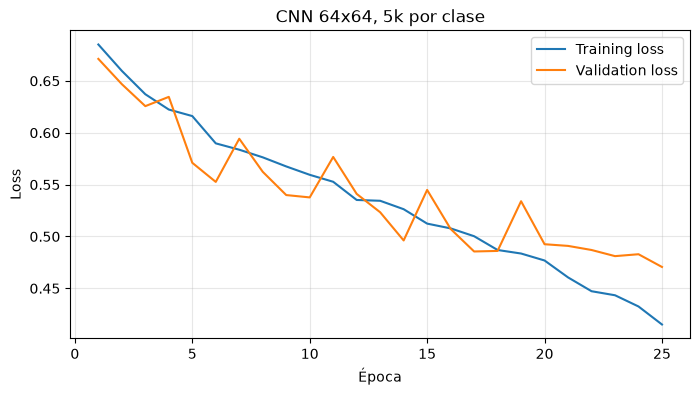

In [8]:
import matplotlib.pyplot as plt

epocas = range(1, len(historial_train) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epocas, historial_train, label='Training loss')
plt.plot(epocas, historial_valid, label='Validation loss')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.title('CNN 64x64, 5k por clase')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 4. Evaluación del modelo

In [9]:
# 1. Variables de control
test_loss = 0.0
class_correct = [0.0, 0.0]
class_total = [0.0, 0.0]
classes = ['fake', 'real']
batch_size = 16  # Cambiar este número si el batch_size es diferente

model.load_state_dict(torch.load('model_64x64_5k.pt'))   # carga los pesos de la mejor época

model.eval() # Modo evaluación

# Desactivamos el cálculo de gradientes para ahorrar memoria y acelerar la evaluación
with torch.no_grad():
    for data, target in test_loader:
        if train_on_gpu:
            data, target = data.cuda(), target.cuda()
            
        output = model(data)
        loss = criterion(output, target)
        test_loss += loss.item() * data.size(0)
        
        # Obtener la clase predicha
        _, pred = torch.max(output, 1)
        correct_tensor = pred.eq(target.data.view_as(pred))
        
        if train_on_gpu:
            correct = np.squeeze(correct_tensor.cpu().numpy())
        else:
            correct = np.squeeze(correct_tensor.numpy())
            
        # Acumular aciertos por clase
        for i in range(len(target)):
            label = target.data[i]
            class_correct[label] += correct[i].item() if correct.ndim > 0 else correct.item()
            class_total[label] += 1

# 2. Calcular pérdidas y precisión globales
# test_loss = test_loss / len(test_loader.dataset)
test_loss = test_loss / len(test_sampler)
print(f'Test Loss: {test_loss:.6f}\n')

# Precisiones por cada clase individual
for i in range(2):
    if class_total[i] > 0:
        acc = 100 * class_correct[i] / class_total[i]
        print(f'Test Accuracy of {classes[i]:>5s}: {acc:2.0f}% ({int(class_correct[i])}/{int(class_total[i])})')
    else:
        print(f'Test Accuracy of {classes[i]:>5s}: N/A (sin ejemplos)')

# Precisión global total
total_correct = np.sum(class_correct)
total_samples = np.sum(class_total)
overall_acc = 100. * total_correct / total_samples
print(f'\nTest Accuracy (Overall): {overall_acc:2.0f}% ({int(total_correct)}/{int(total_samples)})')

Test Loss: 0.496510

Test Accuracy of  fake: 77% (782/1012)
Test Accuracy of  real: 74% (733/988)

Test Accuracy (Overall): 76% (1515/2000)


      precision  recall  f1-score  support
fake      0.754   0.773     0.763     1012
real      0.761   0.742     0.751      988

Accuracy: 0.757


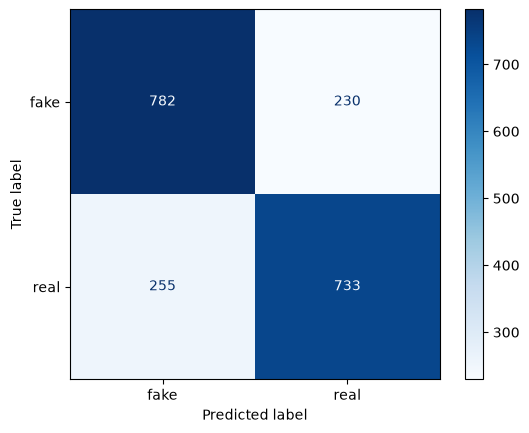

In [13]:
# Métricas y matriz de confusión
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

clases = eval_data.classes   # ['fake', 'real']

# Predicciones de la red sobre todo el conjunto de test
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for data, target in test_loader:
        if train_on_gpu:
            data = data.cuda()
        y_pred += model(data).argmax(dim=1).cpu().tolist()
        y_true += target.tolist()

# Tabla de métricas por clase
p, r, f, s = precision_recall_fscore_support(y_true, y_pred)
print(pd.DataFrame({'precision': p, 'recall': r, 'f1-score': f, 'support': s}, index=clases).round(3))
print(f'\nAccuracy: {accuracy_score(y_true, y_pred):.3f}')

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=clases, cmap='Blues')
plt.show()

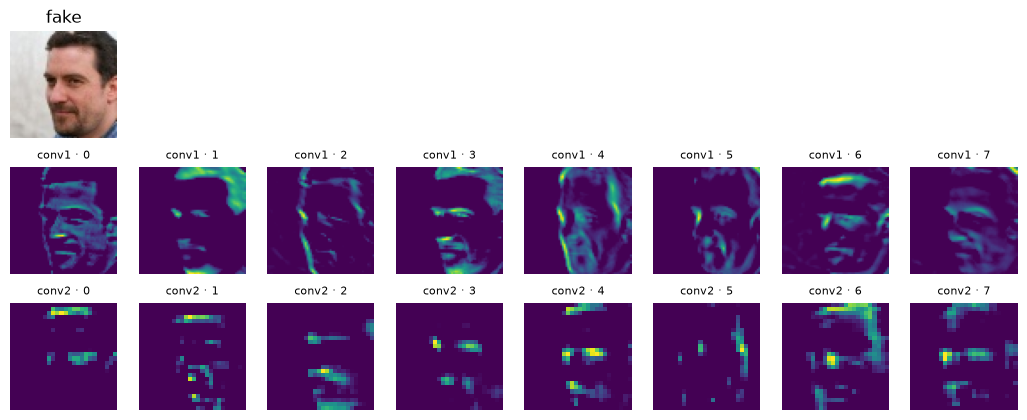

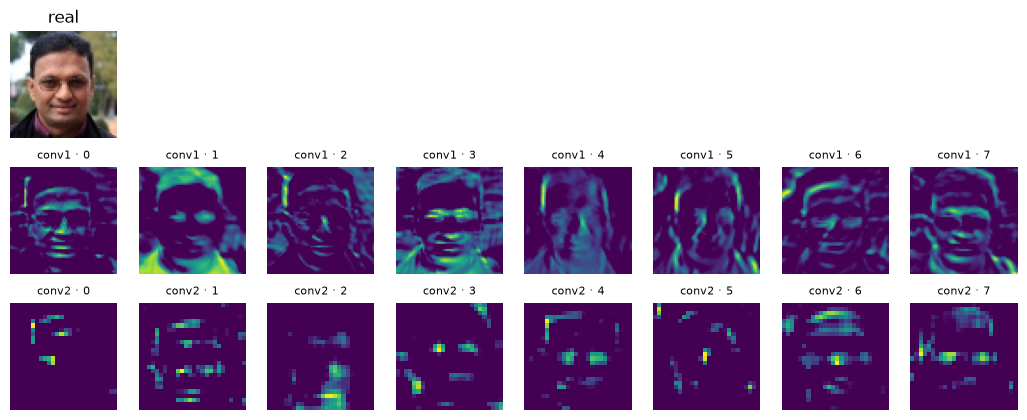

In [11]:
# Mapas de activación: qué detectan los primeros filtros de conv1 y conv2

def mostrar_activaciones(idx):
    x = eval_data[idx][0].unsqueeze(0)
    if train_on_gpu:
        x = x.cuda()
    with torch.no_grad():
        mapas1 = F.relu(model.conv1(x))                    # salida de conv1
        mapas2 = F.relu(model.conv2(model.pool(mapas1)))   # salida de conv2

    fig, axes = plt.subplots(3, 8, figsize=(13, 5))
    for ax in axes.ravel():
        ax.axis('off')
    axes[0, 0].imshow((x[0].cpu().permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1))
    axes[0, 0].set_title(clases[eval_data.targets[idx]])
    for k in range(8):
        axes[1, k].imshow(mapas1[0, k].cpu(), cmap='viridis')
        axes[1, k].set_title(f'conv1 · {k}', fontsize=8)
        axes[2, k].imshow(mapas2[0, k].cpu(), cmap='viridis')
        axes[2, k].set_title(f'conv2 · {k}', fontsize=8)
    plt.show()

idx_fake = next(i for i in test_idx if eval_data.targets[i] == 0)
idx_real = next(i for i in test_idx if eval_data.targets[i] == 1)
mostrar_activaciones(idx_fake)
mostrar_activaciones(idx_real)

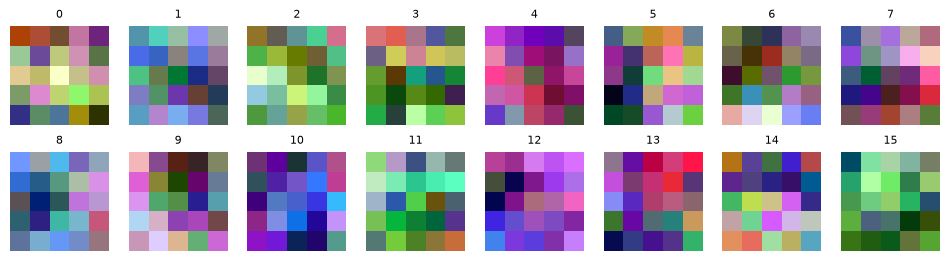

In [12]:
# Los 16 kernels que ha aprendido conv1 (cada uno es de 5x5x3, se dibuja en color)
pesos = model.conv1.weight.detach().cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for k, ax in enumerate(axes.ravel()):
    kernel = pesos[k].permute(1, 2, 0)
    kernel = (kernel - kernel.min()) / (kernel.max() - kernel.min())   # a rango [0, 1]
    ax.imshow(kernel)
    ax.set_title(str(k), fontsize=8)
    ax.axis('off')
plt.show()